# Saturn on human tonsil Sprox-seq: RNA and protein, with protein complexes held out

This tutorial runs Saturn on section B1 of the Sprox-seq human tonsil data (Wang, Xia et al., Cell 2026; GEO GSE304749), the data
of Fig. 5 of the Saturn manuscript. Sprox-seq measures three layers on the same Visium spot: mRNA, surface proteins, and protein
complexes, read out as proximity ligation (PLA) products between antibody pairs.

Section B1 has 3,204 spots in tissue, 38,606 genes, 46 antibody probes and 1,692 PLA products. The fit sees RNA and the
protein abundance summed from the PLA products. The individual products never enter the loss, so we can use them afterwards as
held-out features along each axis.

We are going to build the RNA and protein targets, fit Saturn with the published settings and compare it with the published fit,
call domains along each axis, annotate them, fit proteins and genes as functions of the axis, test the held-out complexes against
a spatial null, look at cell-cell contact complexes, and ask what the cross pathways explain. The notebook takes 6 to 20 min, depending on machine load,
on a CPU.

The notebook reads the GEO matrices and the published result tables from `SATURN_DATA`. Install Saturn from the repository root
with `pip install -e ".[gaston]"`.

## Data preprocessing

Let's first load the packages. A CPU fit depends on the thread count as well as on the seed. The published fit ran with 4 torch
threads and `OMP_NUM_THREADS` unset, so we remove the thread variables before torch is imported and pass `threads=4` to the fit.

In [1]:
import os
for v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.pop(v, None)
import json, re
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.io import mmread
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
from threadpoolctl import threadpool_limits

import saturn
from saturn import crossterm as CT, piecewise as pw

DATA = Path(os.environ.get("SATURN_DATA", "/mnt/HDD2B/Users/yancui"))
RAW = DATA / "external_data/sproxseq"
PUB = DATA / "Hole/gaston_mix_mm/results/real_saturn"     # published results, used only for the comparisons
FIG = DATA / "Saturn/published_figures/fig5"
OUT = Path("outputs/tutorial_sproxseq_rna_protein"); OUT.mkdir(parents=True, exist_ok=True)

published_p46 = np.load(PUB / "targets_sproxseq_B1_p46.npz", allow_pickle=True)      # targets before depth regression
published_dr = np.load(PUB / "targets_sproxseq_B1_p46_dr.npz", allow_pickle=True)    # the targets of the published fit

Now the raw files of section B1: the Visium RNA triplet, the spot positions and the PLA count matrix. We keep the spots that are in
tissue and present in both layers. The coordinates are `(col, -row)` in full-resolution pixels.

In [2]:
GSM = RAW / "GSM9156294_B1"
barcodes = pd.read_csv(f"{GSM}_barcodes.tsv.gz", header=None)[0].astype(str).values
features = pd.read_csv(f"{GSM}_features.tsv.gz", sep="\t", header=None)
gene_names = features[1].astype(str).values
X_all = sp.csr_matrix(mmread(f"{GSM}_matrix.mtx.gz").T)                              # spots x genes
pos = pd.read_csv(f"{GSM}_tissue_positions.csv.gz", index_col=0)
pla = pd.read_csv(RAW / "GSM9156303_B1-PLA_count_matrix.txt.gz", sep="\t", index_col=0)   # products x spots

in_tissue = set(pos.index[pos.in_tissue == 1]) & set(pla.columns)
bc = [b for b in barcodes if b in in_tissue]
X = X_all[pd.Index(barcodes).get_indexer(bc)]
pla = pla[bc]
coords = np.c_[pos.loc[bc, "pxl_col_in_fullres"].values.astype(float), -pos.loc[bc, "pxl_row_in_fullres"].values.astype(float)]
coords_z = saturn.zscore_coords(coords)

print("spots", len(bc), " genes", X.shape[1], " PLA products", pla.shape[0])
print("same barcodes as published:", bc == published_dr["barcodes"].astype(str).tolist(),
      " coords_z max|diff| to published:", np.abs(coords_z - published_dr["coords_z"]).max())

spots 3204  genes 38606  PLA products 1692
same barcodes as published: True  coords_z max|diff| to published: 0.0


A PLA product is named `<probeA>:<probeB>`, where a probe is a protein with an optional `_A`/`_B` suffix. The abundance of a probe is
the sum of all products that contain it, counted in either position, as the authors do. This gives 46 probe marginals, isotype
controls included. These marginals are the protein input. The products themselves stay out of the fit.

In [3]:
tokens = np.array([p.split(":") for p in pla.index])
probes = sorted(set(tokens.ravel()))
C = pla.values.T.astype(float)                                                       # spots x products
M = np.column_stack([C[:, tokens[:, 0] == p].sum(1) + C[:, tokens[:, 1] == p].sum(1) for p in probes])
print(len(probes), "probes;", "median PLA reads per spot", np.median(C.sum(1)))
print(probes[:8], "...")

46 probes; median PLA reads per spot 5413.5
['CD11a_B', 'CD147', 'CD19', 'CD20', 'CD21', 'CD23', 'CD24_A', 'CD24_B'] ...


Saturn fits low-dimensional continuous targets, one per modality. `protein_clr_pca` is the target function for protein or ADT counts:
a centred log ratio per spot followed by PCA, scaled globally so that each component keeps its share of the variance. This call
is deterministic, so we can compare it directly with the published target.

In [4]:
Y_P_raw, info_P = saturn.protein_clr_pca(sp.csr_matrix(M), K=10)
print("Y_Protein max|diff| to published:", np.abs(Y_P_raw - published_p46["Y_Protein"]).max())
print("depth_Protein max|diff| to published:", np.abs(info_P["depth"] - published_p46["depth_Protein"]).max())

Y_Protein max|diff| to published: 0.0
depth_Protein max|diff| to published: 0.0


`rna_glmpc_real` is the RNA target: Poisson GLM-PCA on the 3,000 most variable genes. **It starts from an unseeded `np.random` draw, so
every run returns a different target, and the fit depends on that draw.** We run it here to show the call, and compare the fresh
factors with the published ones. Each fresh component is matched to its closest published component. The call takes a few minutes,
and `threadpool_limits` only keeps it from using every core.

In [5]:
with threadpool_limits(16, user_api="blas"):
    Y_R_fresh, info_R = saturn.rna_glmpc_real(X, K=10)
Y_R_published = published_p46["Y_RNA"]

cc = np.abs(np.corrcoef(Y_R_fresh.T, Y_R_published.T)[:10, 10:])
print("fresh GLM-PCs, best |r| to a published component:", cc.max(1).round(3).tolist())
print("depth_RNA max|diff| to published:", np.abs(info_R["depth"] - published_p46["depth_RNA"]).max())

      glmpca converged with penalty=1


fresh GLM-PCs, best |r| to a published component: [0.865, 0.81, 0.832, 0.694, 0.415, 0.709, 0.672, 0.599, 0.762, 0.305]
depth_RNA max|diff| to published: 0.0


From here on we use the paper's draw, so that everything below can be checked against the manuscript. A reader without the published
file would continue with `Y_R_fresh`, and the last part of this tutorial says what that changes.

`check_target` reports how strongly each leading component follows sequencing depth (`depth_corr`, `depth_leak`) and how spatially
structured it is (`moran`). Depth is RNA UMIs for RNA and PLA reads for protein.

In [6]:
depth_R, depth_P = info_R["depth"], info_P["depth"]
print("RNA    ", saturn.check_target(Y_R_published, depth=depth_R, coords=coords))
print("Protein", saturn.check_target(Y_P_raw, depth=depth_P, coords=coords))

RNA     {'var_share': [0.4106, 0.2406, 0.1297, 0.0453, 0.0406, 0.0343, 0.0311, 0.0283, 0.0206, 0.0189], 'elbow': None, 'depth_corr': [0.704, 0.398, 0.21, 0.118, 0.199], 'depth_leak': 0.704, 'moran': 0.887}
Protein {'var_share': [0.3036, 0.2174, 0.1342, 0.1152, 0.0688, 0.0459, 0.0389, 0.0295, 0.0242, 0.0223], 'elbow': None, 'depth_corr': [0.252, 0.29, 0.345, 0.07, 0.034], 'depth_leak': 0.345, 'moran': 0.738}


Both targets carry depth, so we regress each modality's own log depth out of its components and rescale with `scale_target`. The
package has no function for this step, so it is written out. On another dataset, regressing only RNA moved the depth confound onto the protein
axis, so both modalities are regressed. The strongest correlation of a leading component with log depth falls from 0.704 to 0.115 for RNA and from 0.345 to 0.16 for protein. After this, the targets equal the published ones.

In [7]:
def regress_depth(Y, depth):
    ld = np.log1p(np.asarray(depth, float)); A = np.c_[np.ones_like(ld), ld]
    Y = np.asarray(Y, float); Y = Y - A @ np.linalg.lstsq(A, Y, rcond=None)[0]
    return saturn.scale_target(Y, "global")

Y_R, Y_P = regress_depth(Y_R_published, depth_R), regress_depth(Y_P_raw, depth_P)
targets, modalities = [Y_R, Y_P], ["RNA", "Protein"]
print("RNA    ", saturn.check_target(Y_R, depth=depth_R, coords=coords))
print("Protein", saturn.check_target(Y_P, depth=depth_P, coords=coords))
print("max|diff| to the published targets: RNA", np.abs(Y_R - published_dr["Y_RNA"]).max(),
      " Protein", np.abs(Y_P - published_dr["Y_Protein"]).max())

RNA     {'var_share': [0.2863, 0.2786, 0.1622, 0.0569, 0.0504, 0.0424, 0.0394, 0.0339, 0.0265, 0.0235], 'elbow': None, 'depth_corr': [0.115, 0.019, 0.058, 0.029, 0.036], 'depth_leak': 0.115, 'moran': 0.822}
Protein {'var_share': [0.3315, 0.1618, 0.1248, 0.1276, 0.0768, 0.0505, 0.0433, 0.0326, 0.027, 0.0242], 'elbow': None, 'depth_corr': [0.135, 0.16, 0.003, 0.137, 0.039], 'depth_leak': 0.16, 'moran': 0.741}
max|diff| to the published targets: RNA 0.0  Protein 0.0


## Fitting Saturn

`saturn.fit` trains the model for each seed and keeps the seed with the lowest whole-section loss. We use the arguments of the
published run: seed 42, CPU, 4 threads, a final refit on all spots for 3,000 epochs, no masks and no tail penalty. This cell takes about
3 to 15 min.

In [8]:
res = saturn.fit(targets, coords_z, modalities, seeds=[42], masks=[None, None], refit_all_epochs=3000, device="cpu", threads=4,
                 lam_tail=0.0, depth=dict(RNA=depth_R, Protein=depth_P))
print("best seed", res.best_seed, " whole-section loss", res.fit_all_by_seed)

best seed 42  whole-section loss [0.8320254683494568]


## Comparing with the published fit

The axes should be equal to the published `axes.csv`, value by value.

In [9]:
pub_axes = pd.read_csv(PUB / "sproxseq_B1_p46_dr/axes.csv", index_col=0).loc[bc]
pub_summary = json.load(open(PUB / "sproxseq_B1_p46_dr/summary.json"))
print(pd.DataFrame([dict(axis=m, max_abs_diff=np.abs(res.axes[:, k] - pub_axes[f"d_{m}"].values).max(),
                         abs_r=abs(np.corrcoef(res.axes[:, k], pub_axes[f"d_{m}"].values)[0, 1]))
                    for k, m in enumerate(modalities)]).to_string(index=False))

   axis  max_abs_diff  abs_r
    RNA  4.440892e-16    1.0
Protein  8.881784e-16    1.0


## Checking the fit

Look at the variance explained (`r2`), the cross-pathway share (`coupling`), the correlation of each axis with depth and the correlation
between the axes. The table prints each value next to its published value.

Saturn explains 0.61 of the RNA target and 0.56 of the protein target. The own axis alone gives 0.44 and 0.43, so the cross term adds to both modalities. The coupling
says that 0.32 of the predicted RNA variance is carried by the protein axis, and 0.27 of the predicted protein variance by the RNA axis. It is a variance share, not a causal arrow.

The axes are nearly independent (Spearman -0.107), so the coupling is identifiable here. `rho_Protein` still follows log PLA depth at 0.38 after the regression, so keep this in mind when reading it.

One value differs in sign: the published `summary.json` stores +0.107, while the published `axes.csv` itself gives -0.107, as the last line below shows. The axes are the same, and nothing downstream reads this field.

In [10]:
rows = []
for m in modalities:
    for key in ("full", "own_axis_only", "other_axes_only"):
        rows.append(dict(item=f"R2 {m} {key}", here=res.r2[m][key], published=pub_summary["R2_whole"][m][key]))
    rows.append(dict(item=f"|axis vs log depth| {m}", here=res.axis_depth_corr[m], published=pub_summary["axis_depth_corr"][m]))
rows.append(dict(item="axis vs axis, Spearman", here=res.axis_axis_corr[0][1], published=pub_summary["axis_axis_corr"][0][1]))
print(pd.DataFrame(rows).round(4).to_string(index=False))
print("\ncoupling (row = modality, column = axis)\n", pd.DataFrame(res.coupling, modalities, modalities).round(4))
print("published coupling", pub_summary["coupling_best"])
print("Spearman computed from the published axes.csv:", round(spearmanr(pub_axes.d_RNA, pub_axes.d_Protein).statistic, 3))

                       item    here  published
                R2 RNA full  0.6106     0.6106
       R2 RNA own_axis_only  0.4418     0.4418
     R2 RNA other_axes_only  0.2778     0.2778
    |axis vs log depth| RNA  0.2274     0.2274
            R2 Protein full  0.5574     0.5574
   R2 Protein own_axis_only  0.4278     0.4278
 R2 Protein other_axes_only  0.2384     0.2384
|axis vs log depth| Protein  0.3823     0.3823
     axis vs axis, Spearman -0.1070     0.1070

coupling (row = modality, column = axis)
             RNA  Protein
RNA      0.6833   0.3167
Protein  0.2726   0.7274
published coupling [[0.6833, 0.3167], [0.2726, 0.7274]]
Spearman computed from the published axes.csv: -0.107


## Compartments from marker genes

To read the axes we need an independent annotation. We call compartments from marker genes on log-normalised RNA, using the authors'
marker lists. A spot is B follicle if its B score is above 0.3, and then takes its best zone (dark zone DZ, light zone LZ or naive
follicle NBC). Remaining spots with a T score above 0.3 are T zone, and the rest are extrafollicular (EF). Spots with a
keratin score above 1.5 are crypt epithelium.

In [11]:
rna = ad.AnnData(X.astype(np.float64), obs=pd.DataFrame(index=bc), var=pd.DataFrame(index=gene_names))
rna.var_names_make_unique()
sc.pp.normalize_total(rna, target_sum=1e4); sc.pp.log1p(rna)

def module_z(genes):
    v = np.asarray(rna[:, [g for g in genes if g in rna.var_names]].X.todense()).mean(1).ravel()
    return (v - v.mean()) / v.std()

S = pd.DataFrame({k: module_z(g) for k, g in dict(DZ=["CXCR4", "AICDA", "MME", "FOXP1"], LZ=["CD83", "LMO2", "BCL2A1"],
                                                  NBC=["IGHD", "FCER2", "TCL1A"], B=["MS4A1", "CD19", "CD79A"],
                                                  T=["CD3E", "CD3D", "CD2"]).items()}, index=bc)
zone = np.where(S.B > 0.3, S[["DZ", "LZ", "NBC"]].idxmax(1), "other")
zone = np.where((zone == "other") & (S["T"] > 0.3), "T", zone)
zone = np.where(zone == "other", "EF", zone)
epithelium = module_z(["KRT5", "KRT13", "KRT4", "KRT14", "SPRR3"]) > 1.5
compartment = np.where(epithelium, "epithelium", zone)
print(pd.Series(compartment).value_counts().to_dict())

pub_spots = pd.read_csv(PUB / "sproxseq_B1_fig5/spots.csv", index_col=0).loc[bc]
print("spots with another compartment than published:", int((compartment != pub_spots.compartment.values).sum()))

{'EF': 929, 'T': 730, 'NBC': 712, 'LZ': 319, 'DZ': 258, 'epithelium': 256}


spots with another compartment than published: 0


The sign of an isodepth is arbitrary, so `orient` aligns each axis with a reference. We orient `rho_RNA` to increase with the distance
to the crypt epithelium, and `rho_Protein` from the T zone to the naive follicle.

rho_RNA vs distance to epithelium, Spearman 0.676
oriented axes max|diff| to the published table: RNA 4.440892098500626e-16  Protein 8.881784197001252e-16


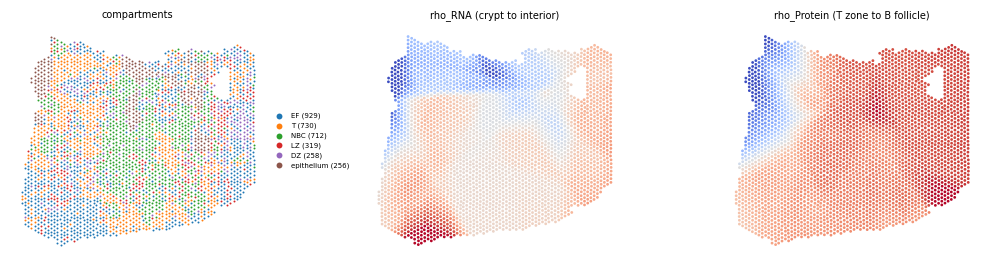

In [12]:
dist_epi = cKDTree(coords[epithelium]).query(coords)[0]
t_to_b = np.select([zone == "T", zone == "NBC"], [-1.0, 1.0], 0.0)
axes = saturn.orient(res.axes.astype(float), np.c_[dist_epi, t_to_b])
d_R, d_P = axes[:, 0], axes[:, 1]
print("rho_RNA vs distance to epithelium, Spearman", round(spearmanr(d_R, dist_epi).statistic, 3))
print("oriented axes max|diff| to the published table: RNA", np.abs(d_R - pub_spots.rho_RNA.values).max(),
      " Protein", np.abs(d_P - pub_spots.rho_Protein.values).max())

fig, ax = plt.subplots(1, 3, figsize=(10, 3))
for k in ["EF", "T", "NBC", "LZ", "DZ", "epithelium"]:
    m = compartment == k; ax[0].scatter(*coords[m].T, s=2, lw=0, label=f"{k} ({m.sum()})", rasterized=True)
ax[0].set_title("compartments", fontsize=7); ax[0].set_aspect("equal"); ax[0].axis("off")
ax[0].legend(fontsize=5, frameon=False, markerscale=3, loc="center left", bbox_to_anchor=(1, .5))
saturn.plotting.spatial(ax[1], coords, d_R, "rho_RNA (crypt to interior)")
saturn.plotting.spatial(ax[2], coords, d_P, "rho_Protein (T zone to B follicle)")
plt.tight_layout(); plt.show()

## Domains along each axis

Each modality is segmented on its own axis with its own targets. `choose_k` takes the elbow of the error curve of GASTON's dynamic
programme, and `gaston_domains` assigns the spots. Domain 0 is the low end of the axis. The elbow gives K = 4 for RNA and K = 3 for protein,
as in the manuscript.

RNA     K 4 [390, 522, 1536, 756]  published K 4 [390, 522, 1536, 756]  labels differing 0
Protein K 3 [1075, 1012, 1117]  published K 3 [1075, 1012, 1117]  labels differing 0


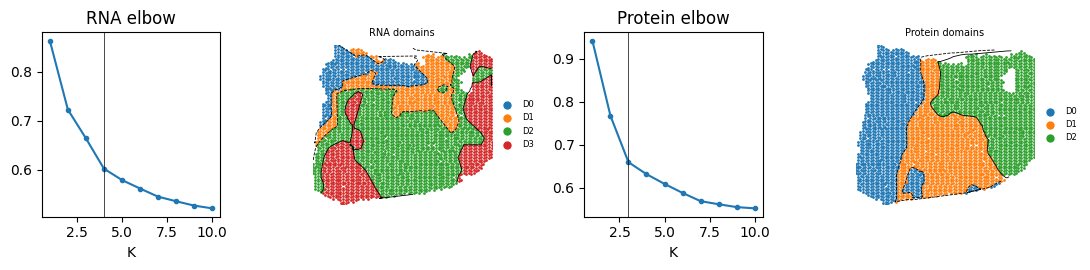

In [13]:
def domains_on(d, Y):
    k, curve = saturn.domains.choose_k(d, np.asarray(Y, float))
    lab = saturn.domains.gaston_domains(d, np.asarray(Y, float), n_domains=k)
    order = np.argsort([np.median(d[lab == i]) for i in range(lab.max() + 1)])          # 0 = low end
    return k, curve, np.argsort(order)[lab]

k_R, curve_R, lab_R = domains_on(d_R, Y_R)
k_P, curve_P, lab_P = domains_on(d_P, Y_P)
bnd_R, bnd_P = saturn.domains.boundaries(d_R, lab_R), saturn.domains.boundaries(d_P, lab_P)

pub_fig5 = json.load(open(PUB / "sproxseq_B1_fig5/summary.json"))
print("RNA     K", k_R, np.bincount(lab_R).tolist(), " published K", pub_fig5["RNA"]["K"], pub_fig5["RNA"]["sizes"],
      " labels differing", int((lab_R != pub_spots.dom_RNA.values).sum()))
print("Protein K", k_P, np.bincount(lab_P).tolist(), " published K", pub_fig5["Protein"]["K"], pub_fig5["Protein"]["sizes"],
      " labels differing", int((lab_P != pub_spots.dom_Protein.values).sum()))

fig, ax = plt.subplots(1, 4, figsize=(11, 2.8))
ax[0].plot(range(1, len(curve_R) + 1), curve_R, "o-", ms=3); ax[0].axvline(k_R, c="k", lw=.5); ax[0].set(title="RNA elbow", xlabel="K")
saturn.plotting.spatial(ax[1], coords, lab_R, "RNA domains", discrete=True, contour_d=d_R, bnds=bnd_R)
ax[2].plot(range(1, len(curve_P) + 1), curve_P, "o-", ms=3); ax[2].axvline(k_P, c="k", lw=.5); ax[2].set(title="Protein elbow", xlabel="K")
saturn.plotting.spatial(ax[3], coords, lab_P, "Protein domains", discrete=True, contour_d=d_P, bnds=bnd_P)
for a_ in (ax[1], ax[3]):
    a_.legend(fontsize=6, frameon=False, markerscale=3, loc="center left", bbox_to_anchor=(1, .5))
plt.tight_layout(); plt.show()

## Domain annotation and markers

`annotate_counts` summarises each domain of a count modality: size, depth, position along the axis, top markers and the number of features
with a slope. The marker compartments go in through `cats`. Here is `rho_RNA`.

In [14]:
tab_R = saturn.annotate.annotate_counts(X, gene_names, lab_R, d_R, "RNA", depth=depth_R, cats=dict(compartment=compartment),
                                        labels={0: "crypt epithelium", 1: "subepithelial IgA plasma", 2: "mantle & T zone", 3: "germinal centre"})
pd.set_option("display.max_colwidth", None)
tab_R

,modality,domain,label,n_spots,isodepth,median_depth,compartment,gradient_feats,markers
0,RNA,0,crypt epithelium,390,"[-2.47, -0.55]",14297.0,"{""DZ"": 0.05, ""EF"": 0.13, ""LZ"": 0.03, ""NBC"": 0.17, ""T"": 0.33, ""epithelium"": 0.29}",386,MT-CO3(+0.7); S100A8(+4.0); MT-CO2(+0.6); MT-CO1(+0.6); MIR205HG(+2.5); MT-ND4(+0.7); MT-ATP6(+0.6); TACSTD2(+3.4)
1,RNA,1,subepithelial IgA plasma,522,"[-0.55, -0.03]",10081.0,"{""DZ"": 0.08, ""EF"": 0.27, ""LZ"": 0.08, ""NBC"": 0.21, ""T"": 0.12, ""epithelium"": 0.24}",395,IGKC(+1.1); IGHG3(+1.6); MIR205HG(+2.7); IGHG1(+1.0); IGLC3(+1.0); IGLC2(+0.9); IGHA1(+1.6); LTF(+2.7)
2,RNA,2,mantle & T zone,1536,"[-0.03, 0.41]",16602.5,"{""DZ"": 0.07, ""EF"": 0.19, ""LZ"": 0.1, ""NBC"": 0.34, ""T"": 0.29, ""epithelium"": 0.01}",410,IGHM(+0.9); LINC00926(+1.1); FCMR(+1.0); CXCL13(+0.7); TXNIP(+0.7); IFITM1(+0.9); BANK1(+1.0); TRIM22(+0.8)
3,RNA,3,germinal centre,756,"[0.41, 1.88]",18053.5,"{""DZ"": 0.12, ""EF"": 0.59, ""LZ"": 0.15, ""NBC"": 0.02, ""T"": 0.13, ""epithelium"": 0.0}",460,IRAG2(+1.4); CR2(+0.9); RGS13(+1.9); HMGB2(+1.3); PLCG2(+1.0); HMCES(+1.8); IGHG1(+0.7); SERPINA9(+2.3)


For a continuous modality, use `annotate_continuous`, which ranks markers by a Welch t and counts sloped features with Gaussian fits. Protein values
here are CLR values per target protein: we sum the `_A` and `_B` probes of each target, and take the log1p minus the mean log1p of the spot.
The isotype controls count in the spot mean, as in the target, but they are not features.

In [15]:
targets_prot = sorted({p.split("_")[0] for p in probes})
P_counts = np.column_stack([M[:, [p.split("_")[0] == t for p in probes]].sum(1) for t in targets_prot])
pub_prot = np.load(PUB / "sproxseq_B1_fig5/proteins.npz", allow_pickle=True)
print(len(targets_prot), "targets; counts max|diff| to published", np.abs(P_counts - pub_prot["counts"]).max())

L = np.log1p(P_counts); clr = L - L.mean(1, keepdims=True)
keep = [i for i, t in enumerate(targets_prot) if "IgG" not in t]
V, prot_names = clr[:, keep], np.array(targets_prot)[keep]

tab_P = saturn.annotate.annotate_continuous(V, prot_names, lab_P, d_P, "Protein", depth=depth_P, cats=dict(compartment=compartment),
                                            labels={0: "T / Tfh-FDC", 1: "naive mantle B", 2: "CD9+ CD38+ surface"})
tab_P

33 targets; counts max|diff| to published 0.0


,modality,domain,label,n_spots,isodepth,median_depth,compartment,gradient_feats,markers
0,Protein,0,T / Tfh-FDC,1075,"[-6.95, -0.50]",13704.0,"{""DZ"": 0.06, ""EF"": 0.4, ""LZ"": 0.1, ""NBC"": 0.08, ""T"": 0.31, ""epithelium"": 0.06}",27,"IgD (-0.51, t-42); CD20 (-0.37, t-38); CD32 (-0.43, t-38); CD19 (-0.24, t-37); PDL2 (+0.16, t+31); CD86 (+0.14, t+27); CD28 (+0.20, t+26); CD279 (+0.24, t+26)"
1,Protein,1,naive mantle B,1012,"[-0.50, 0.37]",10346.0,"{""DZ"": 0.05, ""EF"": 0.16, ""LZ"": 0.08, ""NBC"": 0.43, ""T"": 0.26, ""epithelium"": 0.01}",28,"IgD (+0.58, t+44); ICAM1 (-0.25, t-35); CD19 (+0.21, t+30); CD9 (-0.36, t-30); VCAM1 (-0.25, t-29); CD20 (+0.27, t+28); ITGA4 (+0.11, t+25); CD32 (+0.25, t+24)"
2,Protein,2,CD9+ CD38+ surface,1117,"[0.38, 1.76]",8756.0,"{""DZ"": 0.13, ""EF"": 0.3, ""LZ"": 0.12, ""NBC"": 0.17, ""T"": 0.12, ""epithelium"": 0.16}",28,"CD9 (+0.48, t+31); CD279 (-0.33, t-31); CD38 (+0.19, t+24); CD147 (+0.18, t+23); CD3 (-0.26, t-21); CD4 (-0.13, t-16); CD28 (-0.15, t-16); ICAM1 (+0.14, t+15)"


The labels are the names used in the manuscript, and the tables suggest where they come from. Along `rho_RNA`, domain 0 has epithelial and myeloid markers (S100A8, MIR205HG, TACSTD2) with mitochondrial genes,
domain 1 immunoglobulin genes (IGHA1, IGHG3, IGKC), domain 2 B-cell and mantle genes (IGHM, FCMR, BANK1, CXCL13), and domain 3 germinal-centre genes (RGS13, SERPINA9).
Domain composition is mixed: only 0.29 of the spots in domain 0 are called epithelium, and 0.59 of domain 3 fall in the residual EF class of the marker calls.

Along `rho_Protein`, domain 0 has PD-L2, CD86, CD28 and PD-1 (CD279) with low IgD, domain 1 has IgD, CD19, CD20 and CD32, and domain 2 has CD9, CD38 and CD147.

The composition of each domain can be checked against the published summary.

In [16]:
for m, lab in (("RNA", lab_R), ("Protein", lab_P)):
    here = {k: pd.Series(compartment[lab == k]).value_counts(normalize=True).round(2).head(4).to_dict() for k in range(lab.max() + 1)}
    print(m, "composition equal to published:", {str(k): v for k, v in here.items()} == pub_fig5[m]["composition"])

RNA composition equal to published: True
Protein composition equal to published: True


## Feature functions along an axis

`saturn.piecewise` fits every feature in every domain along the axis, behind GASTON's likelihood-ratio gate, so a flat domain gets a slope of 0. For
continuous values the function is `fit_gauss`: a per-domain OLS with an F test. `annotate.screen` runs it over all features and ranks them by the
number of sloped domains and the binned R2. We use the protein CLR values along `rho_Protein`.

feature  variance  n_sloped_domains    R2
   LFA1    0.0236                 3 0.913
   CD21    0.0966                 3 0.908
   CD35    0.1634                 3 0.901
  VCAM1    0.0979                 3 0.881
   CD19    0.0492                 3 0.879
   CD32    0.1341                 3 0.828
  CD11a    0.0432                 3 0.810
HLADPRQ    0.0509                 3 0.784

proteins with a slope in at least one domain: 29 of 29


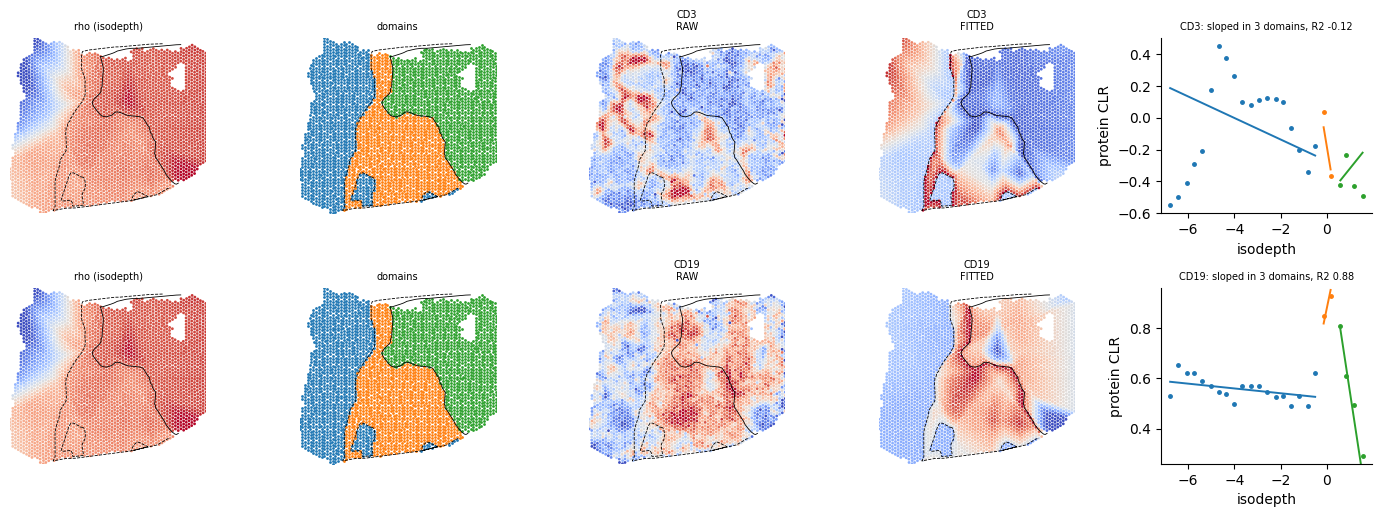

In [17]:
scr, slope_g, inter_g, cand = saturn.annotate.screen(V, prot_names, lab_P, d_P, kind="gauss")
print(scr.drop(columns=["_i", "slopes"]).head(8).to_string(index=False))

slope_P, inter_P = pw.fit_gauss(V, lab_P, d_P)
print("\nproteins with a slope in at least one domain:", int((pw.n_sloped(slope_P) > 0).sum()), "of", V.shape[1])

show = [list(prot_names).index(p) for p in ("CD3", "CD19")]
fig = saturn.plotting.function_figure(coords, d_P, lab_P, V, slope_P, inter_P, prot_names, show, bnds=bnd_P, unit="protein CLR")
plt.show()

CD19 follows a line in each domain (binned R2 0.88). CD3 does not (binned R2 -0.12): it rises and then falls inside domain 0, and a single line per domain cannot follow that, so the gate keeps a slope that fits the binned values worse than their mean. A negative binned R2 is a warning to read the feature from its map, not from the fitted function.

Counts can use the Poisson fit, with the library size as an offset. The manuscript draws CXCL13 and BCL6 along `rho_RNA`, and LFA-1 and CD19 protein
along `rho_Protein`, with `fit_poisson`, so we compare those R2 values with the published ones. `binned_r2` computes the R2 on the rate in 25 equal-width
bins. Protein here has the summed counts and no isotype exclusion in the library.

      feature  n_sloped    R2  n_sloped_pub  R2_pub
       CXCL13         4 0.758             4   0.758
         BCL6         3 0.926             3   0.926
LFA-1 protein         3 0.898             3   0.898
 CD19 protein         3 0.912             3   0.912


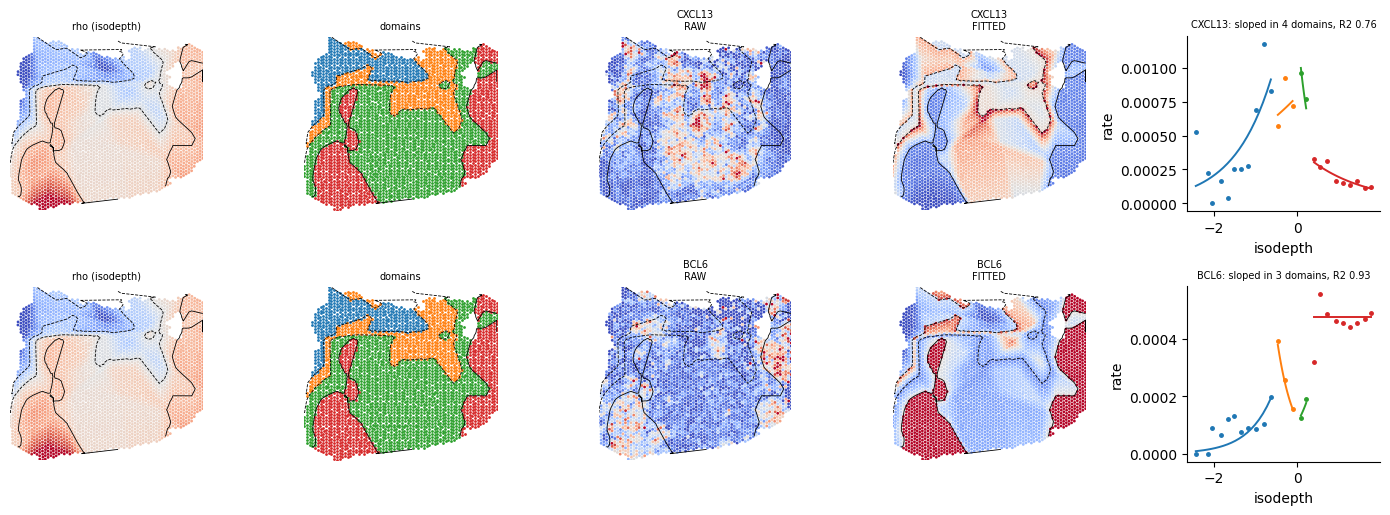

In [18]:
fig5_part1 = json.load(open(FIG / "fig5_part1.json"))["stats"]["e"]
X_csc, lib_R = X.tocsc().astype(float), np.asarray(X.sum(1)).ravel().clip(1).astype(float)
lib_P = P_counts.sum(1).clip(1)
rows = []
for name, title, Yc, lib, names, lab, d in [("CXCL13", "CXCL13", X_csc, lib_R, gene_names, lab_R, d_R),
                                            ("BCL6", "BCL6", X_csc, lib_R, gene_names, lab_R, d_R),
                                            ("LFA1", "LFA-1 protein", P_counts, lib_P, np.array(targets_prot), lab_P, d_P),
                                            ("CD19", "CD19 protein", P_counts, lib_P, np.array(targets_prot), lab_P, d_P)]:
    j = int(np.where(names == name)[0][0])
    c = np.asarray(Yc[:, j].todense()).ravel() if sp.issparse(Yc) else Yc[:, j]
    sl, it = pw.fit_poisson(c[:, None], lib, lab, d)
    r2 = pw.binned_r2(c, d, lab, sl[0], it[0], 25, lib=lib, link="log")[0]
    rows.append(dict(feature=title, n_sloped=int(pw.n_sloped(sl)[0]), R2=round(r2, 3), n_sloped_pub=fig5_part1[title]["n_sloped"], R2_pub=fig5_part1[title]["R2"]))
print(pd.DataFrame(rows).to_string(index=False))

j = [int(np.where(gene_names == g)[0][0]) for g in ("CXCL13", "BCL6")]
sl, it = pw.fit_poisson(np.asarray(X_csc[:, j].todense()), lib_R, lab_R, d_R)
fig = saturn.plotting.function_figure(coords, d_R, lab_R, np.asarray(X_csc[:, j].todense()), sl, it, gene_names[j], [0, 1], bnds=bnd_R,
                                      lib=lib_R, link="log", unit="rate")
plt.show()

## Held-out complexes along each axis

The PLA products were never in the loss, so they can test what each axis carries. The statistic is **isotype-corrected specificity**. For a complex
`a:b` in a set of spots, it is the pooled `log2((O+1)/(E+1))` minus the same quantity for the mouse-IgG isotype products of each partner, averaged over the two
partners. `O` is the PLA reads, and `E` is the per-spot independence expectation `row_a * col_b / total`. Without the isotype term, a complex with a rare partner
looks enriched wherever that partner is rare, because non-specific ligation rises there.

The package has no function for this, so it is written here. Probe suffixes are dropped, control products are excluded, and complexes need at
least 2,000 reads.

In [19]:
strip = lambda t: re.sub(r"_[AB]$", "", t)
A, B = np.array([strip(t) for t in tokens[:, 0]]), np.array([strip(t) for t in tokens[:, 1]])
ISO, CTRL, MIN_READS = ["mIgG1", "mIgG2a", "mIgG2b"], ["mIgG1", "mIgG2a", "mIgG2b", "HIgG"], 2000

rows_t = {t: C[:, A == t].sum(1) for t in set(A)}; cols_t = {t: C[:, B == t].sum(1) for t in set(B)}
tot = C.sum(1).clip(1)
pairs = sorted({(a, b) for a, b in zip(A, B) if a not in CTRL and b not in CTRL})
O = np.column_stack([C[:, (A == a) & (B == b)].sum(1) for a, b in pairs])
E = np.column_stack([rows_t[a] * cols_t[b] / tot for a, b in pairs])
tg = sorted({x for p in pairs for x in p})
IO, IE = [], []
for x in tg:
    ps = {(a, b) for a, b in zip(A, B) if (a == x and b in ISO) or (b == x and a in ISO)}
    IO.append(sum(C[:, (A == a) & (B == b)].sum(1) for a, b in ps)); IE.append(sum(rows_t[a] * cols_t[b] / tot for a, b in ps))
IO, IE = np.column_stack(IO), np.column_stack(IE)
reads_ok = O.sum(0) >= MIN_READS
pairs, O, E = [p for p, k in zip(pairs, reads_ok) if k], O[:, reads_ok], E[:, reads_ok]
names_cx = [f"{a}:{b}" for a, b in pairs]
ia, ib = np.array([tg.index(a) for a, _ in pairs]), np.array([tg.index(b) for _, b in pairs])

def specificity(H, O=O, E=E, ia=ia, ib=ib):
    """H: spots x groups, 0/1. Returns groups x complexes."""
    lo = np.log2((H.T @ O + 1) / (H.T @ E + 1)); li = np.log2((H.T @ IO + 1) / (H.T @ IE + 1))
    return lo - 0.5 * (li[:, ia] + li[:, ib])

pub_layers = np.load(PUB / "sproxseq_B1_fig5/layers.npz", allow_pickle=True)
print(len(names_cx), "complexes; same names as published:", names_cx == pub_layers["pairs"].astype(str).tolist(),
      "; O/E/IO/IE max|diff|", [float(np.abs(a - pub_layers[k]).max()) for a, k in ((O, "O"), (E, "E"), (IO, "IO"), (IE, "IE"))])

645 complexes; same names as published: True ; O/E/IO/IE max|diff| [0.0, 0.0, 0.0, 7.105427357601002e-15]


We compute specificity in 8 equal-count bins of each axis and take the slope against the bin centre. Isodepths are spatially autocorrelated, so a plain test on spots
would be far too liberal. The null is 200 rotations of the axis field (`crossterm.rotate`), which destroy the alignment with the tissue and keep the autocorrelation. The p
value is two-sided, and at p < 0.05 a set of unrelated complexes should give about 5%.

In [20]:
N_BINS, N_ROT, N_PROF = 8, 200, 30

def eq_bins(t, nb):
    return np.eye(nb)[np.minimum((np.argsort(np.argsort(t)) * nb) // len(t), nb - 1)]

def slope_of(Sp, nb=N_BINS):
    c = np.arange(nb) - (nb - 1) / 2
    return (Sp * c[:, None]).sum(0) / (c ** 2).sum()

cx, profile = {}, {}
with threadpool_limits(16, user_api="blas"):
    for m, d in (("RNA", d_R), ("Protein", d_P)):
        obs = slope_of(specificity(eq_bins(d, N_BINS)))
        rng = np.random.default_rng(0)
        null = np.array([slope_of(specificity(eq_bins(CT.rotate(coords, d, rng), N_BINS))) for _ in range(N_ROT)])
        p = ((np.abs(null) >= np.abs(obs)[None]).sum(0) + 1) / (N_ROT + 1)
        cx[m] = pd.DataFrame(dict(slope=obs, p=p, reads=O.sum(0)), index=names_cx)
        profile[m] = specificity(eq_bins(d, N_PROF))

rows = []
for m in modalities:
    T_pub = pd.read_csv(PUB / f"sproxseq_B1_fig5/complexes_{m}.csv", index_col=0).loc[names_cx]
    rows.append(dict(axis=m, n_complexes=len(names_cx), hits=int((cx[m].p < 0.05).sum()), frac_p05=round((cx[m].p < 0.05).mean(), 4),
                     published=round(pub_fig5[m]["frac_p05"], 4), slope_max_diff=np.abs(cx[m].slope - T_pub.slope).max(),
                     p_max_diff=np.abs(cx[m].p - T_pub.p).max()))
print(pd.DataFrame(rows).to_string(index=False))

   axis  n_complexes  hits  frac_p05  published  slope_max_diff   p_max_diff
    RNA          645   148    0.2295     0.2295    1.595946e-16 1.110223e-16
Protein          645    45    0.0698     0.0698    2.359224e-16 1.110223e-16


Of the 645 complexes, 148 (22.9%) change along `rho_RNA` at rotation p < 0.05, and 45 (7.0%) change along `rho_Protein`. The first is above the 5% expected by chance. **The second is near chance: 5% of 645 is about 32 complexes, so on this fit the complex layer changes little along `rho_Protein`.**
These are nominal p values: with 200 rotations the smallest possible p is 0.005, and no multiple-testing correction is applied. Both fractions depend on the GLM-PCA draw, as the last section shows.

Below, the left panel shows the two fractions and the heatmaps show the steepest hits on each axis. The heatmap for `rho_Protein` shows the steepest of few hits, so most of them may be false positives.

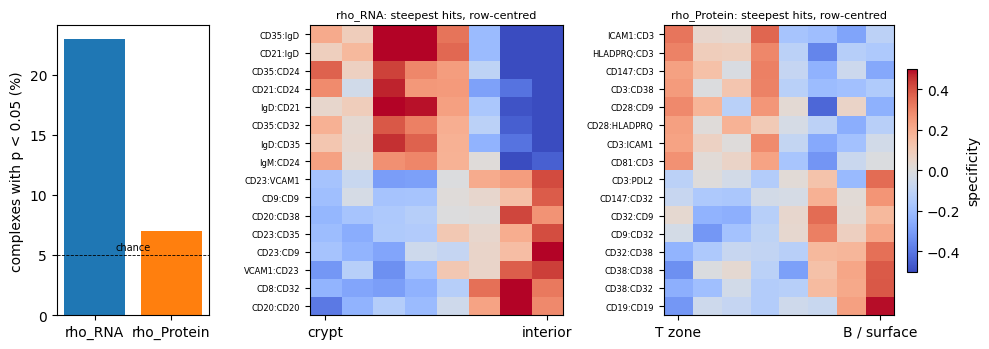

steepest toward the low end of rho_RNA: ['CD35:IgD', 'CD21:IgD', 'CD35:CD24', 'CD21:CD24', 'IgD:CD21', 'CD35:CD32']
steepest toward the high end of rho_RNA: ['CD20:CD20', 'CD8:CD32', 'VCAM1:CD23', 'CD23:CD9', 'CD23:CD35', 'CD20:CD38']


In [21]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3.6), gridspec_kw=dict(width_ratios=[.6, 1, 1]))
ax[0].bar(range(2), [100 * (cx[m].p < 0.05).mean() for m in modalities], color=["C0", "C1"]); ax[0].axhline(5, c="k", lw=.6, ls="--")
ax[0].set_xticks(range(2)); ax[0].set_xticklabels(["rho_RNA", "rho_Protein"]); ax[0].set_ylabel("complexes with p < 0.05 (%)"); ax[0].text(.5, 5.4, "chance", fontsize=7, ha="center")
for a_, m, ends in ((ax[1], "RNA", ("crypt", "interior")), (ax[2], "Protein", ("T zone", "B / surface"))):
    s = cx[m][cx[m].p < 0.05].sort_values("slope"); rows_ = list(s.index[:8]) + list(s.index[::-1][:8][::-1])
    P = pd.DataFrame(profile[m], columns=names_cx)[rows_].values
    P8 = np.array([P[g].mean(0) for g in np.array_split(np.arange(N_PROF), 8)]).T; P8 -= P8.mean(1, keepdims=True)
    im = a_.imshow(P8, cmap="coolwarm", vmin=-.5, vmax=.5, aspect="auto", interpolation="nearest")
    a_.set_yticks(range(len(rows_))); a_.set_yticklabels(rows_, fontsize=6); a_.set_xticks([0, 7]); a_.set_xticklabels(ends)
    a_.set_title(f"rho_{m}: steepest hits, row-centred", fontsize=8)
fig.colorbar(im, ax=ax[2], fraction=.04, label="specificity")
plt.tight_layout(); plt.show()

print("steepest toward the low end of rho_RNA:", cx["RNA"][cx["RNA"].p < .05].sort_values("slope").index[:6].tolist())
print("steepest toward the high end of rho_RNA:", cx["RNA"][cx["RNA"].p < .05].sort_values("slope").index[::-1][:6].tolist())

## Cell-cell contact complexes

Some PLA products pair proteins that sit on two contacting cells, such as the integrin VLA-4 (ITGA4, CD29) with VCAM1, LFA-1 with ICAM1, or MHC-II with CD3 or CD4. The package has
no cell-cell communication (CCC) function, so this is written inline from the table above and `fit_gauss`. First the slopes of the contact pairs measured with this panel, against the published summary.

In [22]:
CONTACT = {"ITGA4:VCAM1": "VLA-4 - VCAM-1", "CD29:VCAM1": "VLA-4 - VCAM-1", "LFA1:ICAM1": "LFA-1 - ICAM-1", "CD3:HLADPRQ": "CD3 - MHC-II", "CD4:HLADPRQ": "CD4 - MHC-II",
           "CD23:CD21": "CD23 - CD21", "CD21:CD35": "CD21 - CD35"}
rows = []
for c, what in CONTACT.items():
    row = dict(complex=c, what=what)
    for m in modalities:
        row[f"slope_{m}"], row[f"p_{m}"] = round(cx[m].loc[c, "slope"], 4), round(cx[m].loc[c, "p"], 3)
        row[f"p_{m}_pub"] = round(pub_fig5[m]["ccc"][c]["p"], 3)
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))

    complex           what  slope_RNA  p_RNA  p_RNA_pub  slope_Protein  p_Protein  p_Protein_pub
ITGA4:VCAM1 VLA-4 - VCAM-1    -0.0382  0.005      0.005        -0.0176      0.279          0.279
 CD29:VCAM1 VLA-4 - VCAM-1    -0.0419  0.020      0.020        -0.0185      0.393          0.393
 LFA1:ICAM1 LFA-1 - ICAM-1    -0.0059  0.682      0.682        -0.0028      0.751          0.751
CD3:HLADPRQ   CD3 - MHC-II    -0.0045  0.816      0.816        -0.0818      0.055          0.055
CD4:HLADPRQ   CD4 - MHC-II     0.0016  0.945      0.945        -0.0556      0.090          0.090
  CD23:CD21    CD23 - CD21     0.0503  0.090      0.090         0.0235      0.677          0.677
  CD21:CD35    CD21 - CD35     0.0028  0.905      0.905         0.0054      0.846          0.846


A complex can be drawn as a function of the axis, too. Single spots hold few reads, so the specificity is pooled in 30 equal-count bins, each bin takes its majority domain, and `fit_gauss` fits the
bins per domain with the F-test gate. The map on the left pools each spot with its 6 nearest neighbours, for display only.

    complex    axis  R2_bins  R2_pub      p  p_pub
ITGA4:VCAM1     RNA    0.682   0.682 0.0050 0.0050
 VCAM1:CD23     RNA    0.549   0.549 0.0199 0.0199
HLADPRQ:CD3 Protein    0.527   0.527 0.0498 0.0498
  ICAM1:CD3 Protein    0.442   0.442 0.0498 0.0498


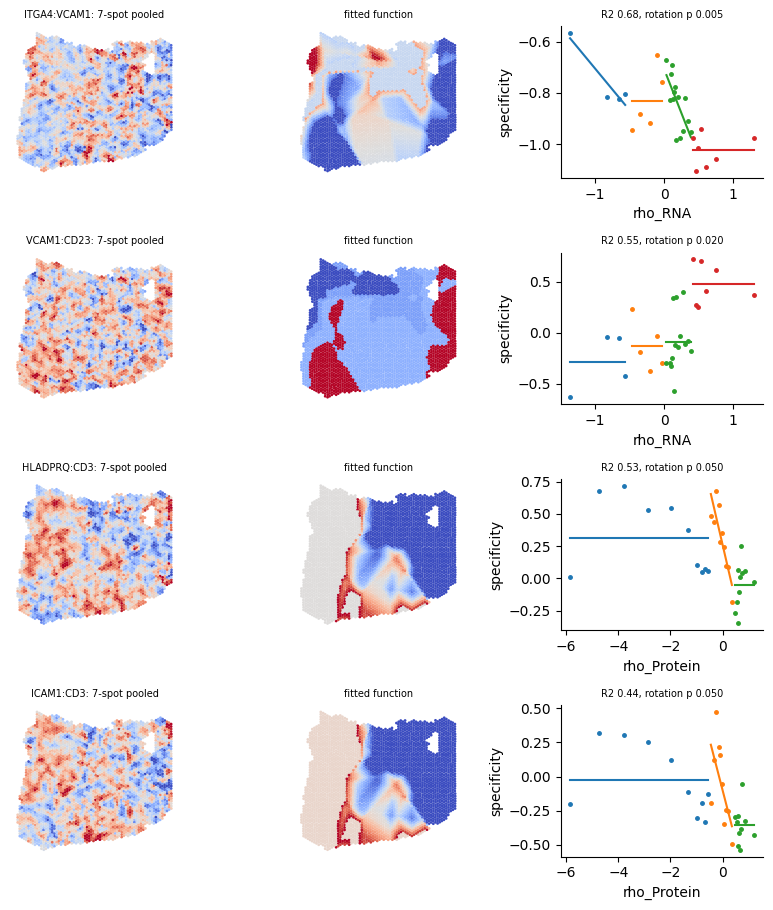

In [23]:
def contact_function(name, d, lab, k=7, nb=N_PROF):
    j = names_cx.index(name); one = lambda H: specificity(H, O[:, [j]], E[:, [j]], ia[[j]], ib[[j]])[:, 0]
    n = len(d); nn = cKDTree(coords).query(coords, k=k)[1]
    H_knn = sp.csr_matrix((np.ones(n * k), (nn.ravel(), np.repeat(np.arange(n), k))), shape=(n, n)).toarray()
    g = np.minimum((np.argsort(np.argsort(d)) * nb) // n, nb - 1)
    by, bx = one(np.eye(nb)[g]), np.array([d[g == i].mean() for i in range(nb)])
    bl = np.array([np.bincount(lab[g == i], minlength=lab.max() + 1).argmax() for i in range(nb)])
    sl, it = pw.fit_gauss(by[:, None], bl, bx, t=0.1); sl, it = sl[0], it[0]
    pred = it[bl] + sl[bl] * bx
    return dict(pooled=one(H_knn), fit=it[lab] + sl[lab] * d, bx=bx, by=by, bl=bl, sl=sl, it=it, r2=1 - ((by - pred) ** 2).sum() / ((by - by.mean()) ** 2).sum())

fig5_part2 = json.load(open(FIG / "fig5_part2.json"))["stats"]["j"]
EXAMPLES = [("RNA", "ITGA4:VCAM1", d_R, lab_R), ("RNA", "VCAM1:CD23", d_R, lab_R), ("Protein", "HLADPRQ:CD3", d_P, lab_P), ("Protein", "ICAM1:CD3", d_P, lab_P)]
fig, ax = plt.subplots(len(EXAMPLES), 3, figsize=(8, 2.3 * len(EXAMPLES))); rows = []
for r, (m, name, d, lab) in enumerate(EXAMPLES):
    F = contact_function(name, d, lab); p = cx[m].loc[name, "p"]
    rows.append(dict(complex=name, axis=m, R2_bins=round(F["r2"], 3), R2_pub=fig5_part2[name]["R2_bins"], p=round(p, 4), p_pub=round(fig5_part2[name]["slope_p"], 4)))
    saturn.plotting.spatial(ax[r, 0], coords, F["pooled"], f"{name}: 7-spot pooled")
    saturn.plotting.spatial(ax[r, 1], coords, F["fit"], "fitted function")
    for k in range(lab.max() + 1):
        q = F["bl"] == k; ax[r, 2].plot(F["bx"][q], F["by"][q], "o", ms=2.5, color=f"C{k}")
        if q.any():
            xs = np.linspace(F["bx"][q].min(), F["bx"][q].max(), 10); ax[r, 2].plot(xs, F["it"][k] + F["sl"][k] * xs, color=f"C{k}")
    ax[r, 2].set(xlabel=f"rho_{m}", ylabel="specificity"); ax[r, 2].set_title(f"R2 {F['r2']:.2f}, rotation p {p:.3f}", fontsize=7); ax[r, 2].spines[["top", "right"]].set_visible(False)
print(pd.DataFrame(rows).to_string(index=False))
plt.tight_layout(); plt.show()

Both VLA-4 complexes change along `rho_RNA` (ITGA4:VCAM1 p 0.005, CD29:VCAM1 p 0.020), with higher specificity toward the crypt end. LFA1:ICAM1 does not change along either axis (p 0.682 and 0.751). None of the seven pairs reaches p < 0.05 along `rho_Protein`: CD3:HLADPRQ
has p 0.055 and CD4:HLADPRQ p 0.090. In the second table, HLADPRQ:CD3 and ICAM1:CD3 on `rho_Protein` sit at p 0.0498, which is borderline, and the p values are nominal among 645 complexes.

These results describe where a contact complex changes along an axis. They do not show that the cells interact there, and **they do not show that Saturn finds contact complexes better than other methods**. This tutorial runs no comparison, and the lab's separate benchmark on this section did not find Saturn's axes better than baseline axes at predicting these complexes.

## What the cross pathways explain

`saturn.crossterm` asks where and for which genes one axis explains the other modality. `spot_decomposition` splits the model at each spot. `gain_RNA` is the local gain from the protein axis: the drop in
error when the cross term is allowed to vary, averaged over the 25 nearest spots. `signs` carries the orientation we chose above.

R2 RNA {'full': 0.6105608960291697, 'own_only': 0.441754188754478}  published {'full': 0.6105608960291697, 'own_only': 0.441754188754478}
R2 Protein {'full': 0.5574136636800273, 'own_only': 0.4277967806992562}  published {'full': 0.5574136636800273, 'own_only': 0.4277967806992562}
gain max|diff| to published: RNA 2.220446049250313e-16  Protein 1.1102230246251565e-16


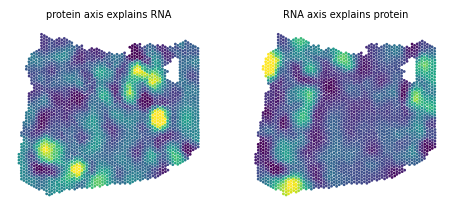

In [24]:
signs = [np.sign(np.corrcoef(res.axes[:, k], axes[:, k])[0, 1]) for k in range(2)]
T, S_cross = CT.spot_decomposition(res.model, coords_z, coords, targets, 0, 1, signs)
pub_cross = json.load(open(PUB / "saturn_cross_term/sprox_summary.json"))
pub_T = pd.read_csv(PUB / "saturn_cross_term/sprox_spots.csv", index_col=0).loc[bc]
print("R2 RNA", S_cross["R2_RNA"], " published", pub_cross["R2_RNA"])
print("R2 Protein", S_cross["R2_X"], " published", pub_cross["R2_X"])
print("gain max|diff| to published: RNA", np.abs(T.gain_RNA.values - pub_T.gain_RNA.values).max(), " Protein", np.abs(T.gain_X.values - pub_T.gain_X.values).max())

fig, ax = plt.subplots(1, 2, figsize=(5.6, 2.8))
saturn.plotting.spatial(ax[0], coords, T.gain_RNA, "protein axis explains RNA", cmap="viridis")
saturn.plotting.spatial(ax[1], coords, T.gain_X, "RNA axis explains protein", cmap="viridis")
plt.show()

`gene_cross_test` compares `log1p CPM ~ B(rho_RNA)` with `~ B(rho_RNA) + B(rho_Protein)` for every gene detected in at least 5% of spots, where `B` is a linear term plus hinges. It returns the gain in variance
explained, a partial F test and a Benjamini-Hochberg q value. `steepness_test` asks whether the gain follows the places where one axis changes faster than the other, against rotations of the spot map.

In [25]:
G, prof, tested = CT.gene_cross_test(X, gene_names, T.rho_RNA.values, T.rho_X.values)
G_pub = pd.read_csv(PUB / "saturn_cross_term/sprox_genes.csv")
print(len(G), "genes tested,", int((G.q < 0.05).sum()), "with q < 0.05; published", pub_cross["n_genes"], pub_cross["n_cross_fdr05"])
print("dR2_cross max|diff| to published:", np.abs(G.dR2_cross.values - G_pub.dR2_cross.values).max(), " same gene order:", (G.gene.values == G_pub.gene.values).all())
display(G.head())

steep = CT.steepness_test(T, nrot=200)
for nm in ("RNA", "X"):
    print(nm, {k: round(v, 3) for k, v in steep[f"steeper_{nm}"].items() if k in ("rho", "p_rot")}, " published",
          {k: round(pub_cross[f"steeper_{nm}"][k], 3) for k in ("rho", "p_rot")})

13100 genes tested, 7543 with q < 0.05; published 13100 7543
dR2_cross max|diff| to published: 9.974659986866641e-17  same gene order: True


,gene,detect,R2_own,R2_own_plus_X,dR2_cross,p,q,cross_sd,cross_r_rhoX
10122,ENSG00000262202,0.945693,0.155824,0.354416,0.198593,1.012751e-181,6.633519e-178,0.345993,0.454537
9120,RPL4,0.993446,0.198582,0.368865,0.170283,1.778731e-161,3.883563e-158,0.235257,-0.426881
1169,MIR205HG,0.317728,0.485212,0.644591,0.159379,2.358714e-252,3.089916e-248,0.480552,0.299403
8881,IGHG3,0.994694,0.250113,0.403603,0.153489,1.100387e-154,1.801883e-151,0.443453,0.592312
9491,RPS15A,0.992197,0.187162,0.339566,0.152404,6.035794e-140,8.785433e-137,0.228849,-0.433808


RNA {'rho': -0.245, 'p_rot': 0.124}  published {'rho': -0.245, 'p_rot': 0.124}
X {'rho': -0.04, 'p_rot': 0.612}  published {'rho': -0.04, 'p_rot': 0.612}


The cross term adds 0.17 of the RNA target variance (0.44 to 0.61) and 0.13 of the protein target variance (0.43 to 0.56). In the gene test, 7,543 of the 13,100 tested genes pass q < 0.05. The partial F test treats spots as independent, so with this many spatially
autocorrelated spots the count is generous: use the test to rank genes by `dR2_cross`, not as a count of cross-regulated genes. The top of the list includes ribosomal genes (RPL4, RPS15A) and an immunoglobulin gene (IGHG3), which suggests broad composition or quality effects rather than specific regulation.

The local gain does not follow the steep places of the other axis here: Spearman -0.245 (rotation p 0.124) for RNA, and -0.04 (rotation p 0.612) for protein.

## Saving the result

`save` writes the model weights, the axes and the summary, and `load_model` reads the weights back for later analyses. We also keep the complex tables.

In [26]:
res.save(str(OUT), coords=coords, barcodes=bc)
for m in modalities:
    cx[m].to_csv(OUT / f"complexes_{m}.csv")
model = saturn.load_model(str(OUT / "saturn_best.pt"), [Y_R.shape[1], Y_P.shape[1]])
print(np.abs(saturn.decompose(model, coords_z)[0] - res.axes).max())

0.0


## How far the numbers depend on the GLM-PCA draw

Everything above uses the paper's GLM-PCA draw. The figure notebook `notebooks/fig5_sproxseq.ipynb` (section 8) runs the same chain on one fresh draw, without the published factors. It is not run here because it takes about 1 h, and these numbers come from that notebook:

| | published draw | one fresh draw |
|---|---|---|
| R2 RNA | 0.611 | 0.632 |
| R2 Protein | 0.557 | 0.563 |
| RNA elbow K | 4 | 3 |
| Protein elbow K | 3 | 3 |
| `rho_RNA` vs published, \|r\| | | 0.77 |
| `rho_Protein` vs published, \|r\| | | 0.88 |
| complexes on `rho_RNA`, p < 0.05 | 22.9% (148) | 20.0% (129), 100 shared |
| complexes on `rho_Protein`, p < 0.05 | 7.0% (45) | 24.0% (155), 16 shared |

The `rho_RNA` result is similar across the two draws. **The `rho_Protein` result is not: 7.0% is near chance, while the fresh draw gives 24.0%, and only 16 of the 45 published hits are shared.** So the statement that `rho_Protein` is near chance holds for the published draw only, and the result depends on the draw. Other draws may differ again.

`rna_glmpc_real` has no seed argument. To reproduce your own analysis, save the target you fitted, as we did here with the published one. When a claim matters, repeat the fit on more than one draw.